# 04  Exploracion y limpieza: Codigo Urbanostico (CABA)

**Dataset:** `data/raw/codigo-urbanistico.csv` (BA Data codigo Urbanistico vigente).

**Objetivo:** explorar la estructura, evaluar la calidad de los datos y generar una version limpia lista para cruzar por `smp` con `epok_fichas` y `habilitaciones`.

**Columnas clave:**
- `smp`  identificador catastral (clave de cruce)
- `uso_1/2/3`  usos permitidos (zonificacion real)
- `fot_em_1`, `fot_pl_1`, `fot_sl_1`  Factor de Ocupaci?n Total (efectiva / planta / subsuelo)
- `uni_edif_1..4`  edificabilidad / altura permitida
- `barrio`, `comuna`  ubicaci?n administrativa
- `rh`, `lep`, `catalogado`, `ensanche`, `apertura`  restricciones


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

RAIZ = next(
    (
        ruta
        for ruta in (Path.cwd(), *Path.cwd().parents)
        if (ruta / "data" / "raw" / "codigo-urbanistico.csv").exists()
    ),
    None,
)
if RAIZ is None:
    raise FileNotFoundError("No se encontro data/raw/codigo-urbanistico.csv desde el directorio actual")

RAW = RAIZ / "data" / "raw" / "codigo-urbanistico.csv"
df = pd.read_csv(RAW, sep=None, engine="python", dtype={"smp": str})
df.shape

(318127, 52)

## 1. Primer vistazo: estructura y tipos de datos

In [2]:
print(f"Filas: {len(df):,}  |  Columnas: {len(df.columns)}")
df.dtypes.to_frame("dtype")

Filas: 318,127  |  Columnas: 52


,dtype
gid,int64
smp,str
seccion,int64
manzana,str
parcela,str
uni_edif_1,float64
uni_edif_2,float64
uni_edif_3,float64
uni_edif_4,float64
uso_1,float64


In [3]:
df.head(3).T

,0,1,2
gid,333267,333302,333417
smp,016-044-038,016-081B-001,016-003-020
seccion,16,16,16
manzana,044,081B,003
parcela,038,001,020
uni_edif_1,17.2,14.6,17.2
uni_edif_2,0.0,0.0,0.0
uni_edif_3,0.0,0.0,0.0
uni_edif_4,0.0,0.0,0.0
uso_1,3.0,1.0,2.0


## 2. Calidad de datos

### 2.1 Valores nulos por columna

In [4]:
nulos = df.isna().sum()
resumen_nulos = pd.DataFrame({"nulos": nulos, "%": (nulos / len(df) * 100).round(2)})
resumen_nulos[resumen_nulos["nulos"] > 0].sort_values("%", ascending=False)

,nulos,%
dist_3_grp,318113,100.00
dist_4_esp,318126,100.00
dist_4_grp,318126,100.00
dist_3_esp,318113,100.00
zona_2,317981,99.95
dist_cpu_2,317649,99.85
dist_2_esp,316317,99.43
dist_2_grp,316316,99.43
microcentr,314613,98.90
plano_l_ob,308601,97.01


> Las columnas `dist_` son **esparsas a proposito**: solo se completan cuando la parcela esto cerca de una avenida (zona de influencia). No es un error de calidad.

### 2.2 Clave `smp`: nulos, duplicados y formato

In [5]:
fmt_ok = df["smp"].str.match(r"^\d{3}-[\w]+-\w+$").mean()
print(f"Nulos en smp      : {df['smp'].isna().sum()}")
print(f"Duplicados en smp : {df['smp'].duplicated().sum()}")
print(f"Formato valido    : {fmt_ok:.1%}")
print(f"Comunas distintas : {df['comuna'].nunique()}")

Nulos en smp      : 0
Duplicados en smp : 0
Formato valido    : 100.0%
Comunas distintas : 15


## 3. Exploracion de variables clave

### 3.1 Zonificacion  usos permitidos (`uso_1`)

In [6]:
df["uso_1"].value_counts(dropna=False).sort_index().to_frame("parcelas")

,parcelas
uso_1,
0.0,33693
1.0,85042
2.0,117704
3.0,41825
4.0,39862
NaN,1


### 3.2 Edificabilidad  altura (`uni_edif_1`)

In [7]:
df["uni_edif_1"].describe().to_frame()

,uni_edif_1
count,318126.000000
mean,14.587808
std,8.184940
min,0.000000
25%,9.000000
50%,14.600000
75%,17.200000
max,38.000000


### 3.3 Factor de Ocupacion Total (FOT)

In [8]:
df[["fot_em_1", "fot_pl_1", "fot_sl_1"]].describe().T

,count,mean,std,min,25%,50%,75%,max
fot_em_1,318126.0,1.816305,1.357162,-1.0,1.2,1.6,3.0,18.29
fot_pl_1,318126.0,1.794345,1.515834,0.0,1.0,1.2,3.0,18.29
fot_sl_1,318126.0,1.662735,1.430221,0.0,0.0,1.2,3.0,18.29


### 3.4 Distribucin por comuna

In [9]:
df["comuna"].value_counts().sort_index().to_frame("parcelas")

,parcelas
comuna,
1,12449
2,6376
3,11824
4,25264
5,14598
6,13429
7,24765
8,19254
9,33861


## 4. Limpieza y estandarizacion

Pasos:
1. Recortar espacios y convertir marcadores textuales (`nan`, `none`, `null`, `na`, `n/a`) en valores nulos reales.
2. Estandarizar `smp` en mayusculas y convertir las variables numericas con `errors="coerce"`.
3. Eliminar solo filas sin datos utilizables en las columnas clave (`smp`, `uso_1`, `uni_edif_1`, `fot_em_1`, `comuna`); no descartar filas por nulos en columnas opcionales o dispersas.
4. Conservar valores negativos de FOT para que queden visibles en la auditoria; no se imputan ni corrigen sin una regla de negocio confirmada.

In [10]:
limpio = df.copy()

for columna in limpio.select_dtypes(include=["object", "string"]).columns:
    limpio[columna] = limpio[columna].astype("string").str.strip()
    limpio[columna] = limpio[columna].replace(
        r"(?i)^(?:nan|none|null|na|n/a)?$", pd.NA, regex=True
    )

if "smp" in limpio.columns:
    limpio["smp"] = limpio["smp"].str.upper()

columnas_numericas = [
    "uni_edif_1", "uso_1", "fot_em_1", "fot_pl_1", "fot_sl_1", "comuna"
]
for columna in columnas_numericas:
    if columna in limpio.columns:
        limpio[columna] = pd.to_numeric(limpio[columna], errors="coerce")

cols_clave = ["smp", "uso_1", "uni_edif_1", "fot_em_1", "comuna"]
antes = len(limpio)
limpio = limpio.dropna(subset=cols_clave).copy()
eliminadas = antes - len(limpio)

limpio["smp"] = limpio["smp"].astype("string")
limpio["comuna"] = limpio["comuna"].astype("Int64")
limpio = limpio.reset_index(drop=True)

print(f"Filas eliminadas (claves nulas o no numericas): {eliminadas}")
print(f"Filas finales                                  : {len(limpio):,}")
print(f"smp unica                                      : {limpio['smp'].is_unique}")
marcadores_nulos = r"(?i)(nan|none|null|na|n/a)"
restantes = sum(
    limpio[columna].str.fullmatch(marcadores_nulos, na=False).sum()
    for columna in limpio.select_dtypes(include=["object", "string"]).columns
)
print(f"Marcadores literales de nulo restantes         : {restantes}")

Filas eliminadas (claves nulas o no numericas): 1
Filas finales                                  : 318,126
smp unica                                      : True


Marcadores literales de nulo restantes         : 0


### Validaci?n final de la clave de cruce

In [11]:
assert limpio["smp"].is_unique, "smp debe ser unico"
assert limpio["smp"].notna().all(), "smp no puede tener nulos"
print("OK: smp unica y completa  lista para cruzar con epok_fichas y habilitaciones.")

OK: smp unica y completa  lista para cruzar con epok_fichas y habilitaciones.


## 5. Guardar version limpia

In [12]:
OUT = RAIZ / "data" / "processed" / "codigo_urbanistico_limpio.csv"
OUT.parent.mkdir(parents=True, exist_ok=True)
limpio.to_csv(OUT, index=False)
print(f"Guardado: {OUT}")
print(f"Filas: {len(limpio):,} | Columnas: {len(limpio.columns)}")

Guardado: /home/matias17/Descargas/Proyectos Data/innovalab/data/processed/codigo_urbanistico_limpio.csv
Filas: 318,126 | Columnas: 52


## 6. Cuantiles y EDA visual

Los percentiles resumen la edificabilidad y los factores FOT sin imputar valores. La auditoria IQR cuenta candidatos fuera de `Q1 - 1.5 x IQR` y `Q3 + 1.5 x IQR`; no son errores automaticamente. Los graficos muestran distribuciones, valores atipicos, registros por comuna y columnas con faltantes. Las columnas `dist_*` pueden tener nulos estructurales.

Cuantiles y diagnostico IQR (los candidatos no se eliminan automaticamente)


,min,Q1,mediana,Q3,P90,P95,P99,max,negativos,candidatos_IQR
uni_edif_1,0.0,9.0,14.6,17.2,22.80,31.20,38.0,38.00,0,23194
fot_em_1,-1.0,1.2,1.6,3.0,3.50,4.13,5.0,18.29,7708,838
fot_pl_1,0.0,1.0,1.2,3.0,3.53,4.13,7.0,18.29,0,8023
fot_sl_1,0.0,0.0,1.2,3.0,3.49,4.13,5.0,18.29,0,303


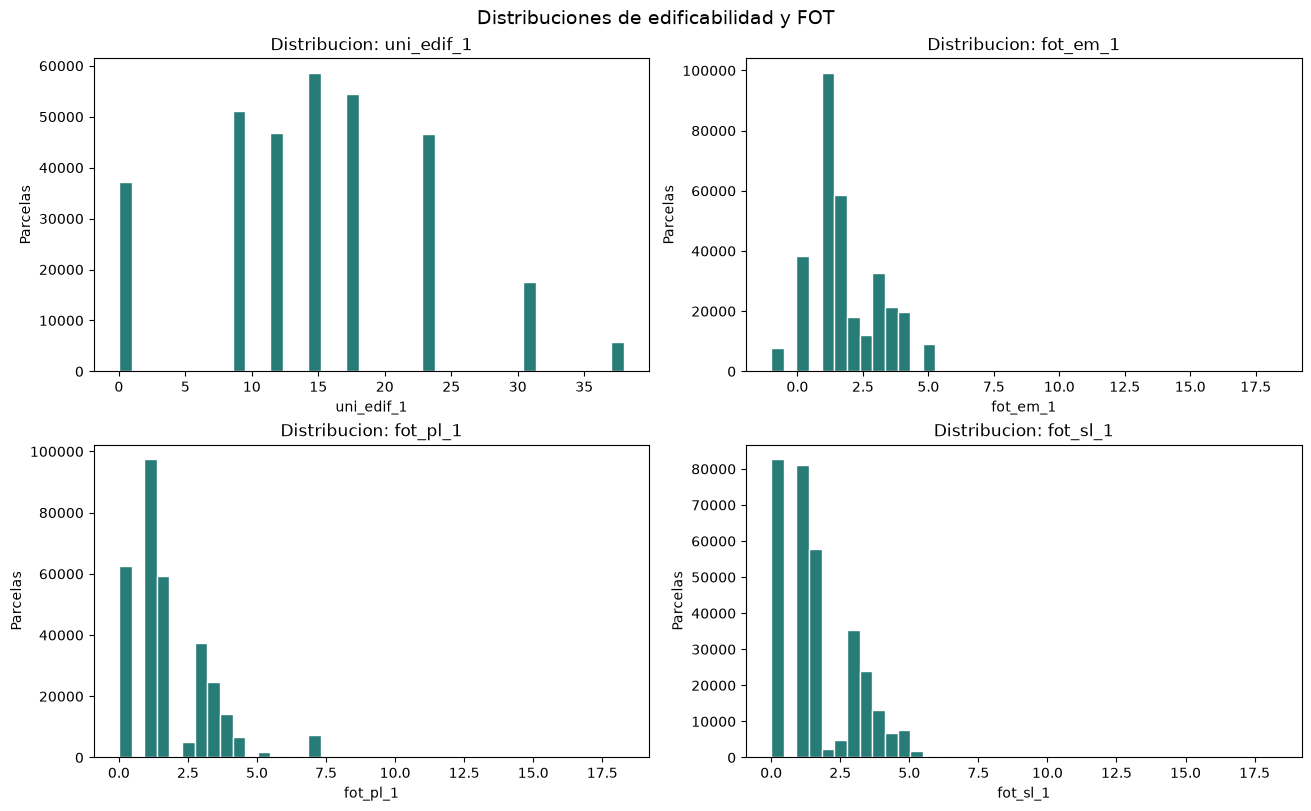

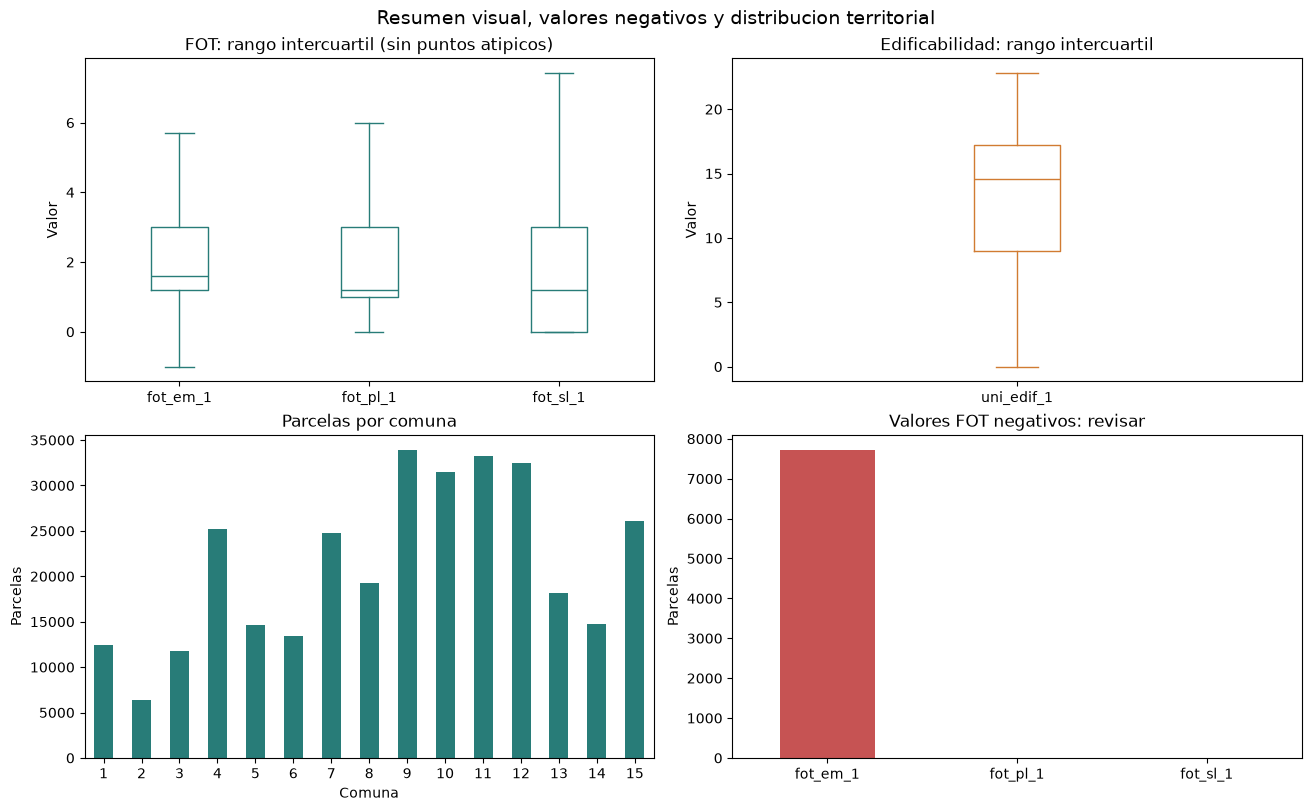

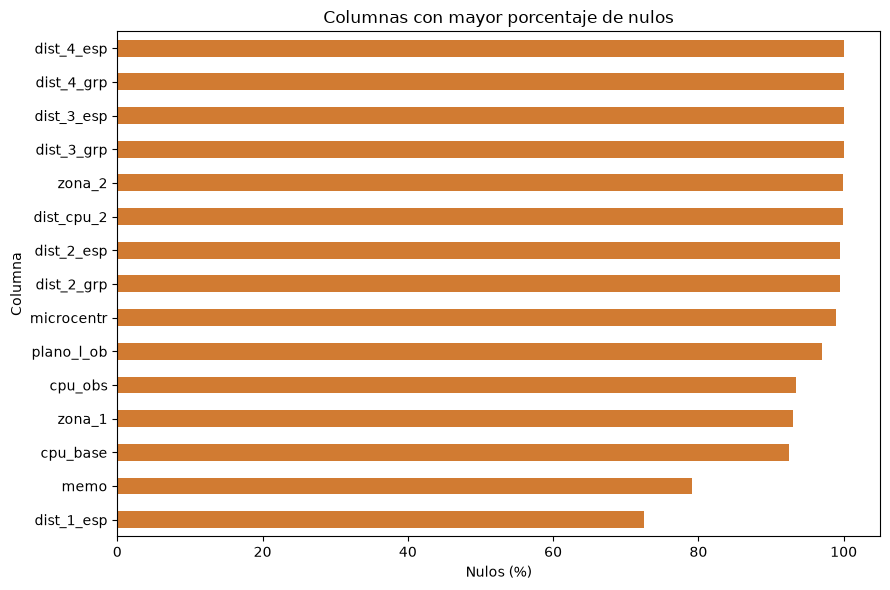

In [13]:
import matplotlib.pyplot as plt

variables_cuantiles = [
    columna
    for columna in ["uni_edif_1", "fot_em_1", "fot_pl_1", "fot_sl_1"]
    if columna in limpio.columns
]
percentiles = [0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]
nombres_percentiles = ["min", "Q1", "mediana", "Q3", "P90", "P95", "P99", "max"]
cuantiles = limpio[variables_cuantiles].quantile(percentiles).T
cuantiles.columns = nombres_percentiles

resumen_atipicos = {}
for columna in variables_cuantiles:
    q1 = limpio[columna].quantile(0.25)
    q3 = limpio[columna].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    resumen_atipicos[columna] = {
        "negativos": int((limpio[columna] < 0).sum()),
        "candidatos_IQR": int(
            ((limpio[columna] < limite_inferior) | (limpio[columna] > limite_superior)).sum()
        ),
    }

resumen_atipicos = pd.DataFrame(resumen_atipicos).T
print("Cuantiles y diagnostico IQR (los candidatos no se eliminan automaticamente)")
display(cuantiles.join(resumen_atipicos))

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for eje, columna in zip(axes.flat, variables_cuantiles):
    eje.hist(limpio[columna].dropna(), bins=40, color="#287C78", edgecolor="white")
    eje.set_title(f"Distribucion: {columna}")
    eje.set_xlabel(columna)
    eje.set_ylabel("Parcelas")
fig.suptitle("Distribuciones de edificabilidad y FOT", fontsize=14)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
columnas_fot = [c for c in ["fot_em_1", "fot_pl_1", "fot_sl_1"] if c in limpio.columns]
if columnas_fot:
    limpio[columnas_fot].plot.box(ax=axes[0, 0], showfliers=False, color="#287C78")
    axes[0, 0].set_title("FOT: rango intercuartil (sin puntos atipicos)")
    axes[0, 0].set_ylabel("Valor")
if "uni_edif_1" in limpio.columns:
    limpio["uni_edif_1"].plot.box(ax=axes[0, 1], showfliers=False, color="#D17B32")
    axes[0, 1].set_title("Edificabilidad: rango intercuartil")
    axes[0, 1].set_ylabel("Valor")
if "comuna" in limpio.columns:
    conteo_comunas = limpio["comuna"].value_counts().sort_index()
    conteo_comunas.plot.bar(ax=axes[1, 0], color="#287C78")
    axes[1, 0].set_title("Parcelas por comuna")
    axes[1, 0].set_xlabel("Comuna")
    axes[1, 0].set_ylabel("Parcelas")
    axes[1, 0].tick_params(axis="x", rotation=0)
negativos_fot = (limpio[columnas_fot] < 0).sum() if columnas_fot else pd.Series(dtype="int64")
if not negativos_fot.empty:
    negativos_fot.plot.bar(ax=axes[1, 1], color="#C65353")
    axes[1, 1].set_title("Valores FOT negativos: revisar")
    axes[1, 1].set_ylabel("Parcelas")
    axes[1, 1].tick_params(axis="x", rotation=0)
fig.suptitle("Resumen visual, valores negativos y distribucion territorial", fontsize=14)
plt.show()

porcentaje_nulos = limpio.isna().mean().mul(100).sort_values(ascending=False)
porcentaje_nulos = porcentaje_nulos[porcentaje_nulos > 0].head(15).sort_values()
if not porcentaje_nulos.empty:
    ax = porcentaje_nulos.plot.barh(figsize=(9, 6), color="#D17B32")
    ax.set_title("Columnas con mayor porcentaje de nulos")
    ax.set_xlabel("Nulos (%)")
    ax.set_ylabel("Columna")
    plt.tight_layout()
    plt.show()
else:
    print("No quedan valores nulos en el dataframe limpio.")